# Notebook 22 — Korelasi Data Sentimen (`sentiment_mean`) dengan Labeling

**Tujuan:** menjawab pertanyaan spesifik — seberapa kuat hubungan antara skor sentimen harian (`sentiment_mean`) dengan label arah harga (`label`, naik/turun) yang dipakai sebagai target model?

Notebook ini **reuse langsung** pipeline produksi yang sudah jadi *single source of truth* untuk training/API — bukan reimplementasi/data sintetis:
- `pipeline/feature_engineering/dataset_builder.py::load_joined()` — gabungan OHLCV + `sentiment_mean` (inner join on `Date`)
- `models/lstm/notebook07_common.py::load_split_capped()` — label horizon-N, split kronologis (70/15/15), capping outlier IQR (fit-train-only) — persis logic yang dipakai training Model B (`FinBERT-LSTM`) dan endpoint `/api/v1/data-information/*`

Dua analisis dilakukan:
1. **Korelasi Point-Biserial** `sentiment_mean` vs `label` per split (train/val/test), untuk horizon 1 hari DAN 5 hari — mengukur hubungan linear sentimen-hari-ini dengan arah harga pada horizon target.
2. **Korelasi Lag** `sentiment_mean(t)` vs return harga `k` hari ke depan (k = 0..10) — mengukur apakah efek sentimen (kalau ada) muncul instan atau butuh beberapa hari untuk tercermin di harga.

## Bagian 1 — Setup & Muat Data

Load Model B (OHLCV + `sentiment_mean`) untuk horizon 1 dan horizon 5, pakai fungsi produksi (bukan versi terpisah).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if (Path.cwd() / "notebooks").exists() is False else Path.cwd()
if (PROJECT_ROOT / "pipeline").exists() is False:
    PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from pipeline.feature_engineering.dataset_builder import load_joined
from models.lstm.notebook07_common import load_split_capped

FIG_DIR = PROJECT_ROOT / "notebooks" / "outputs" / "notebook22"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", lambda v: f"{v:.4f}")

CAPPING_COLS = ["Volume", "sentiment_mean"]   # sama seperti Model B di data_information_service.py
HORIZONS = [1, 5]

splits_by_horizon = {}
for h in HORIZONS:
    df_train, df_val, df_test, capping_bounds, n_capped = load_split_capped(load_joined, CAPPING_COLS, horizon=h)
    splits_by_horizon[h] = {"train": df_train, "val": df_val, "test": df_test}
    print(f"Horizon {h} hari — train: {len(df_train)} | val: {len(df_val)} | test: {len(df_test)} baris")

Horizon 1 hari — train: 1068 | val: 229 | test: 230 baris
Horizon 5 hari — train: 1066 | val: 228 | test: 229 baris


In [2]:
print("=== Keseimbangan label (persentase 'Naik') per split & horizon ===")
for h in HORIZONS:
    for split_name, d in splits_by_horizon[h].items():
        up_pct = d["label"].mean() * 100
        print(f"  horizon={h} | {split_name:5s}: {up_pct:.1f}% Naik / {100 - up_pct:.1f}% Turun  (n={len(d)})")

=== Keseimbangan label (persentase 'Naik') per split & horizon ===
  horizon=1 | train: 55.2% Naik / 44.8% Turun  (n=1068)
  horizon=1 | val  : 45.4% Naik / 54.6% Turun  (n=229)
  horizon=1 | test : 56.5% Naik / 43.5% Turun  (n=230)
  horizon=5 | train: 61.7% Naik / 38.3% Turun  (n=1066)
  horizon=5 | val  : 51.3% Naik / 48.7% Turun  (n=228)
  horizon=5 | test : 65.5% Naik / 34.5% Turun  (n=229)


## Bagian 2 — Korelasi Point-Biserial: `sentiment_mean` vs `label`

`label` biner (0/1) dan `sentiment_mean` kontinu → korelasi Point-Biserial (`scipy.stats.pointbiserialr`) adalah ukuran yang tepat (setara Pearson untuk kasus ini). Dihitung terpisah per split supaya konsisten pergeseran hubungan dari train ke test (temuan notebook 11) ikut kelihatan, bukan tertutup oleh angka gabungan.

In [3]:
def interpret_r(r: float) -> str:
    a = abs(r)
    if a < 0.05:
        return "nyaris tidak ada hubungan"
    if a < 0.1:
        return "sangat lemah"
    if a < 0.3:
        return "lemah"
    if a < 0.5:
        return "sedang"
    return "kuat"

rows = []
for h in HORIZONS:
    for split_name, d in splits_by_horizon[h].items():
        r, p = stats.pointbiserialr(d["label"], d["sentiment_mean"])
        rows.append({"horizon": h, "split": split_name, "pearson_r": round(float(r), 4),
                     "p_value": round(float(p), 4), "signifikan_5pct": bool(p < 0.05)})

corr_df = pd.DataFrame(rows)
print("=== Korelasi Point-Biserial sentiment_mean vs label ===")
print(corr_df)

print("\n=== Interpretasi & cek konsistensi arah antar split (per horizon) ===")
for h in HORIZONS:
    sub = corr_df[corr_df["horizon"] == h].set_index("split")
    mean_abs_r = sub["pearson_r"].abs().mean()
    signs = set(np.sign(sub["pearson_r"].values))
    flip_note = "  [!] arah hubungan BERUBAH antar split" if len(signs - {0}) > 1 else ""
    print(f"  horizon={h}: rata-rata |r|={mean_abs_r:.4f} -> {interpret_r(mean_abs_r)}{flip_note}")

=== Korelasi Point-Biserial sentiment_mean vs label ===
   horizon  split  pearson_r  p_value  signifikan_5pct
0        1  train     0.0317   0.3006            False
1        1    val    -0.0348   0.6004            False
2        1   test     0.0280   0.6731            False
3        5  train     0.0270   0.3785            False
4        5    val    -0.0783   0.2390            False
5        5   test     0.0732   0.2702            False

=== Interpretasi & cek konsistensi arah antar split (per horizon) ===
  horizon=1: rata-rata |r|=0.0315 -> nyaris tidak ada hubungan  [!] arah hubungan BERUBAH antar split
  horizon=5: rata-rata |r|=0.0595 -> sangat lemah  [!] arah hubungan BERUBAH antar split


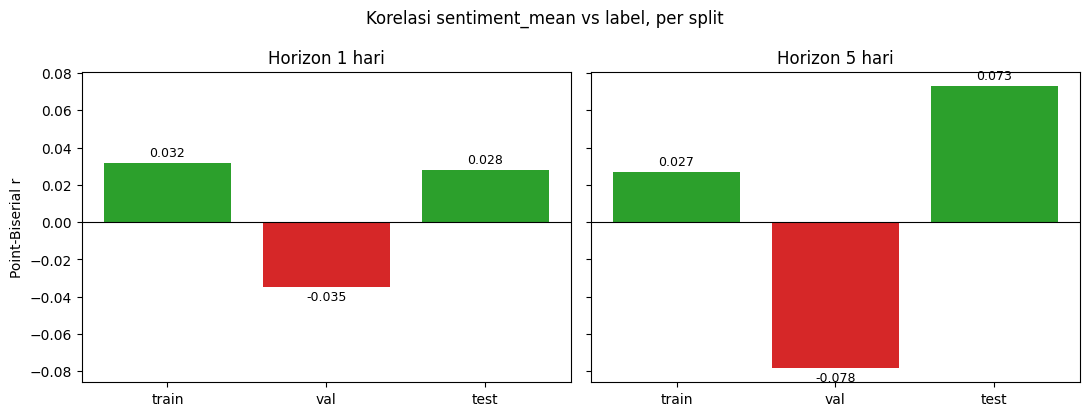

In [4]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(11, 4.2), sharey=True)
for ax, h in zip(axes, HORIZONS):
    sub = corr_df[corr_df["horizon"] == h]
    colors = ["#d62728" if r < 0 else "#2ca02c" for r in sub["pearson_r"]]
    ax.bar(sub["split"], sub["pearson_r"], color=colors)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"Horizon {h} hari")
    ax.set_ylabel("Point-Biserial r" if h == HORIZONS[0] else "")
    for i, r in enumerate(sub["pearson_r"]):
        ax.text(i, r + (0.002 if r >= 0 else -0.002), f"{r:.3f}", ha="center",
                va="bottom" if r >= 0 else "top", fontsize=9)
fig.suptitle("Korelasi sentiment_mean vs label, per split")
fig.tight_layout()
fig.savefig(FIG_DIR / "pointbiserial_sentiment_vs_label.png", dpi=150)
plt.show()

## Bagian 3 — Korelasi Lag: `sentiment_mean(t)` vs Return Harga `k` Hari ke Depan

Kalau sentimen hari ini punya efek ke harga, efeknya bisa muncul instan (`k=0`) atau butuh beberapa hari (`k>0`) untuk tercermin. Dihitung `pearsonr(sentiment_mean, Close.pct_change(1).shift(-k))` untuk k=0..10 hari — mirror metodologi endpoint `/api/v1/data-information/sentiment-lag-correlation`, dihitung baik pada data gabungan penuh (`overall`) maupun per split horizon-1 (train/val/test) untuk cek konsistensi.

In [5]:
MAX_LAG = 10  # sama seperti _MAX_LAG di app/services/data_information_service.py

def lag_series(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for k in range(0, MAX_LAG + 1):
        fwd = df["Close"].pct_change(1).shift(-k)
        valid = df["sentiment_mean"].notna() & fwd.notna()
        if int(valid.sum()) < 10:
            continue
        r, p = stats.pearsonr(df.loc[valid, "sentiment_mean"], fwd[valid])
        rows.append({"lag_days": k, "pearson_r": round(float(r), 4), "p_value": round(float(p), 4)})
    return pd.DataFrame(rows)

df_joined = load_joined()
lag_overall = lag_series(df_joined)

# split horizon=1 dipakai khusus utk breakdown lag per split (konsisten endpoint API)
h1 = splits_by_horizon[1]
lag_by_split = {name: lag_series(d.reset_index(drop=True)) for name, d in h1.items()}

print("=== Korelasi Lag (overall, seluruh data gabungan) ===")
print(lag_overall)

=== Korelasi Lag (overall, seluruh data gabungan) ===
    lag_days  pearson_r  p_value
0          0     0.2202   0.0000
1          1     0.0090   0.7254
2          2     0.0256   0.3182
3          3    -0.0039   0.8779
4          4    -0.0221   0.3896
5          5     0.0035   0.8918
6          6    -0.0031   0.9030
7          7     0.0557   0.0299
8          8     0.0164   0.5237
9          9     0.0182   0.4790
10        10     0.0045   0.8608


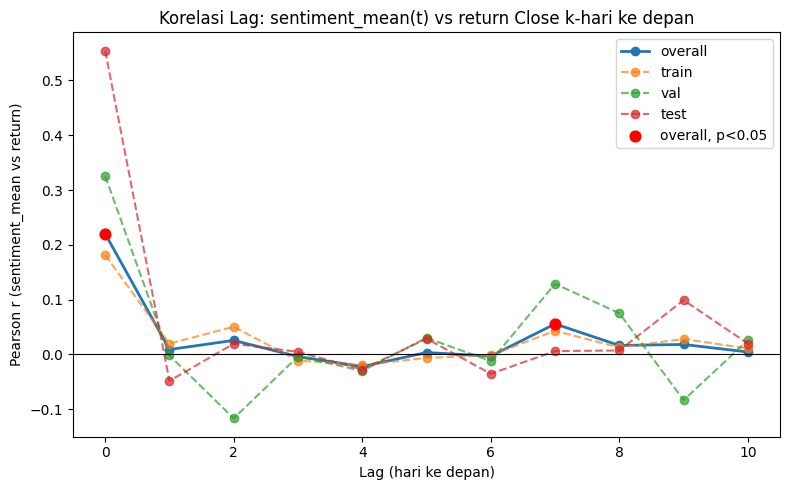

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(lag_overall["lag_days"], lag_overall["pearson_r"], marker="o", label="overall", linewidth=2)
for name, ldf in lag_by_split.items():
    ax.plot(ldf["lag_days"], ldf["pearson_r"], marker="o", linestyle="--", alpha=0.7, label=name)

sig_overall = lag_overall[lag_overall["p_value"] < 0.05]
ax.scatter(sig_overall["lag_days"], sig_overall["pearson_r"], color="red", zorder=5,
           label="overall, p<0.05", s=60)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Lag (hari ke depan)")
ax.set_ylabel("Pearson r (sentiment_mean vs return)")
ax.set_title("Korelasi Lag: sentiment_mean(t) vs return Close k-hari ke depan")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "lag_correlation_sentiment_vs_return.png", dpi=150)
plt.show()

## Bagian 4 — Ringkasan

In [7]:
print("=" * 78)
print("RINGKASAN -- KORELASI sentiment_mean DENGAN LABELING")
print("=" * 78)

for h in HORIZONS:
    sub = corr_df[corr_df["horizon"] == h].set_index("split")
    mean_abs_r = sub["pearson_r"].abs().mean()
    any_sig = bool(sub["signifikan_5pct"].any())
    print(f"\n[Horizon {h} hari] rata-rata |r| point-biserial = {mean_abs_r:.4f}"
          f" ({interpret_r(mean_abs_r)}) | ada split signifikan (p<0.05): {any_sig}")

max_abs_lag_r = lag_overall["pearson_r"].abs().max()
best_lag = lag_overall.loc[lag_overall["pearson_r"].abs().idxmax(), "lag_days"]
print(f"\n[Korelasi Lag] |r| tertinggi = {max_abs_lag_r:.4f} pada lag={best_lag} hari")
print("\nCatatan: sesuai temuan notebook 11/13, sinyal murni OHLCV terbukti lemah dan"
      " korelasi fitur-label bisa berbalik tanda antar split; nilai |r| yang kecil di sini"
      " konsisten dengan pola tersebut -- bukan berarti pipeline salah, tapi hubungan"
      " linear sentimen-vs-label memang lemah pada data ini.")

RINGKASAN -- KORELASI sentiment_mean DENGAN LABELING

[Horizon 1 hari] rata-rata |r| point-biserial = 0.0315 (nyaris tidak ada hubungan) | ada split signifikan (p<0.05): False

[Horizon 5 hari] rata-rata |r| point-biserial = 0.0595 (sangat lemah) | ada split signifikan (p<0.05): False

[Korelasi Lag] |r| tertinggi = 0.2202 pada lag=0 hari

Catatan: sesuai temuan notebook 11/13, sinyal murni OHLCV terbukti lemah dan korelasi fitur-label bisa berbalik tanda antar split; nilai |r| yang kecil di sini konsisten dengan pola tersebut -- bukan berarti pipeline salah, tapi hubungan linear sentimen-vs-label memang lemah pada data ini.


## Bagian 5 — Kesesuaian Arah: `sentiment_mean` Positif vs Harga Hari Itu Positif

Pertanyaan berbeda dari Bagian 2-3: bukan `sentiment_mean` vs label prediksi ke depan (`Close[t+horizon] > Close[t]`), tapi **hari yang sama** — kalau sentimen hari itu positif, apakah harga hari itu juga positif? "Harga hari itu positif" dicek dengan **dua definisi**:
- **Day-over-day**: `Close[t] > Close[t-1]` (return harian, konsisten dengan definisi `label`/`ret_close` yang dipakai di tempat lain pada pipeline ini)
- **Intraday**: `Close[t] > Open[t]` (harga naik dari buka ke tutup pada hari itu sendiri, tidak melihat hari sebelumnya)

`sentiment_mean` dikategorikan **positif** (`sentiment_mean > 0`) vs **negatif/netral** (`sentiment_mean <= 0`) — dua kategori biar sebanding dengan label harga yang juga biner.

In [8]:
df_full = load_joined().copy()
df_full["ret_dod"] = df_full["Close"].pct_change()  # day-over-day, sama definisi dgn ret_close di tempat lain

sentiment_positif = df_full["sentiment_mean"] > 0
harga_naik_dod = df_full["ret_dod"] > 0
harga_naik_intraday = df_full["Close"] > df_full["Open"]

print(f"Total hari (setelah drop NaN ret_dod hari pertama): {df_full['ret_dod'].notna().sum()}")
print(f"Hari sentimen positif : {sentiment_positif.sum()} ({sentiment_positif.mean()*100:.1f}%)")
print(f"Hari harga naik (DoD) : {harga_naik_dod.sum()} ({harga_naik_dod.mean()*100:.1f}%)")
print(f"Hari harga naik (intraday): {harga_naik_intraday.sum()} ({harga_naik_intraday.mean()*100:.1f}%)")

Total hari (setelah drop NaN ret_dod hari pertama): 1527
Hari sentimen positif : 471 (30.8%)
Hari harga naik (DoD) : 824 (53.9%)
Hari harga naik (intraday): 829 (54.3%)


In [9]:
def analisis_kesesuaian(sent_pos, harga_naik, valid_mask, label_harga: str) -> pd.DataFrame:
    s = sent_pos[valid_mask].astype(int)
    h = harga_naik[valid_mask].astype(int)

    ct = pd.crosstab(
        s.map({0: "Sentimen Negatif/Netral", 1: "Sentimen Positif"}),
        h.map({0: "Harga Turun", 1: "Harga Naik"}),
    )
    print(f"=== Tabel Kontingensi: sentiment_mean vs harga ({label_harga}) ===")
    print(ct)

    chi2, p_chi2, dof, expected = stats.chi2_contingency(ct)
    phi, _p_phi = stats.pointbiserialr(s, h)  # setara Pearson utk 2 variabel biner (koefisien phi)
    agreement = float((s == h).mean())

    print(f"\nKoefisien Phi (korelasi 2 variabel biner) : {phi:.4f}")
    print(f"Chi-square test independensi              : chi2={chi2:.4f}, p-value={p_chi2:.4f}")
    print(f"Tingkat kesesuaian arah (agreement rate)   : {agreement*100:.1f}%  (baseline acak/50% jika tidak ada hubungan)")
    print("-" * 78)
    return ct

valid_dod = df_full["ret_dod"].notna()
ct_dod = analisis_kesesuaian(sentiment_positif, harga_naik_dod, valid_dod, "day-over-day")
ct_intraday = analisis_kesesuaian(sentiment_positif, harga_naik_intraday, pd.Series(True, index=df_full.index), "intraday")

=== Tabel Kontingensi: sentiment_mean vs harga (day-over-day) ===
ret_dod                  Harga Naik  Harga Turun
sentiment_mean                                  
Sentimen Negatif/Netral         500          557
Sentimen Positif                324          146

Koefisien Phi (korelasi 2 variabel biner) : 0.2003
Chi-square test independensi              : chi2=60.4156, p-value=0.0000
Tingkat kesesuaian arah (agreement rate)   : 57.7%  (baseline acak/50% jika tidak ada hubungan)
------------------------------------------------------------------------------
=== Tabel Kontingensi: sentiment_mean vs harga (intraday) ===
col_0                    Harga Naik  Harga Turun
sentiment_mean                                  
Sentimen Negatif/Netral         517          540
Sentimen Positif                312          159

Koefisien Phi (korelasi 2 variabel biner) : 0.1606
Chi-square test independensi              : chi2=38.7311, p-value=0.0000
Tingkat kesesuaian arah (agreement rate)   : 55.8%  (ba

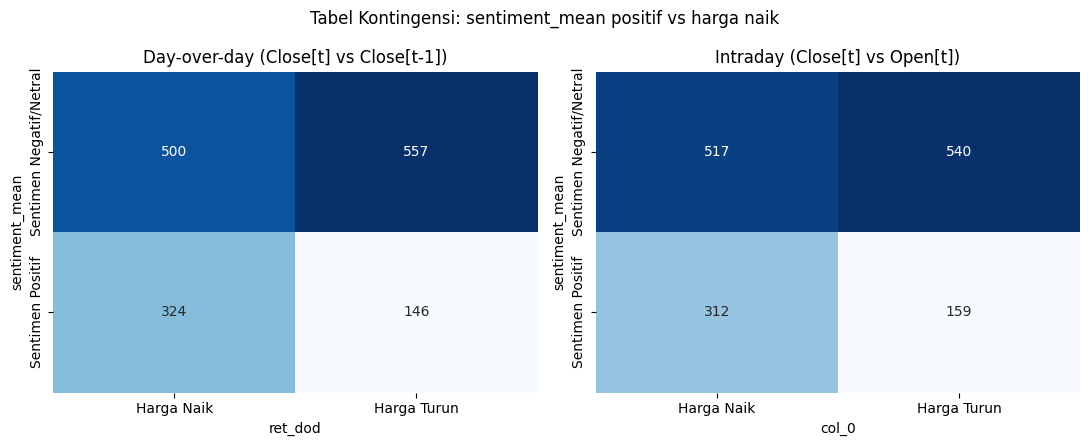

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, ct, title in zip(axes, [ct_dod, ct_intraday], ["Day-over-day (Close[t] vs Close[t-1])", "Intraday (Close[t] vs Open[t])"]):
    sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(title)
fig.suptitle("Tabel Kontingensi: sentiment_mean positif vs harga naik")
fig.tight_layout()
fig.savefig(FIG_DIR / "kontingensi_sentimen_vs_harga_harian.png", dpi=150)
plt.show()

### Ringkasan Bagian 5

Koefisien Phi di sini **secara matematis identik** dengan korelasi Point-Biserial `lag=0` di Bagian 3 (untuk definisi day-over-day) — bedanya di sini `sentiment_mean` **juga** dikategorikan biner (positif/negatif), bukan dipakai sebagai nilai kontinu, supaya bisa dibaca sebagai "tabel kesesuaian arah" yang lebih intuitif: dari semua hari sentimen positif, berapa persen yang harganya juga naik hari itu — dibanding baseline 50% kalau memang tidak ada hubungan.

In [11]:
print("=" * 78)
print("RINGKASAN BAGIAN 5")
print("=" * 78)
for ct, valid_mask, harga_naik, label_harga in [
    (ct_dod, valid_dod, harga_naik_dod, "day-over-day"),
    (ct_intraday, pd.Series(True, index=df_full.index), harga_naik_intraday, "intraday"),
]:
    s = sentiment_positif[valid_mask].astype(int)
    h = harga_naik[valid_mask].astype(int)
    phi, p_phi = stats.pointbiserialr(s, h)
    agreement = float((s == h).mean())
    print(f"[{label_harga}] phi={phi:.4f} (p={p_phi:.4f}) | kesesuaian arah={agreement*100:.1f}%",
          "-> ADA kecenderungan searah" if p_phi < 0.05 else "-> TIDAK signifikan, mendekati kebetulan")

RINGKASAN BAGIAN 5
[day-over-day] phi=0.2003 (p=0.0000) | kesesuaian arah=57.7% -> ADA kecenderungan searah
[intraday] phi=0.1606 (p=0.0000) | kesesuaian arah=55.8% -> ADA kecenderungan searah


## Bagian 6 — Metrik Sederhana: Persentase Harga Naik/Turun per Kategori Sentimen

Koefisien Phi di Bagian 5 sulit dibaca langsung. Di sini angkanya dipecah jadi bentuk persentase yang lebih mudah dibaca: **dari semua hari sentimen POSITIF, berapa persen harganya naik dan berapa persen turun** — dibandingkan dengan hari sentimen NEGATIF/NETRAL. Kalau sentimen benar-benar tidak berpengaruh, kedua kategori seharusnya menghasilkan persentase yang mirip (di sekitar rata-rata keseluruhan).

In [12]:
def ringkas_persentase(sent_pos, harga_naik, valid_mask, label_harga: str) -> pd.DataFrame:
    s = sent_pos[valid_mask]
    h = harga_naik[valid_mask]

    rows = []
    for kategori, mask in [("Sentimen Positif", s), ("Sentimen Negatif/Netral", ~s)]:
        subset = h[mask]
        rows.append({
            "kategori_sentimen": kategori,
            "jumlah_hari": int(mask.sum()),
            "pct_harga_naik": round(float(subset.mean()) * 100, 1),
            "pct_harga_turun": round(float((~subset).mean()) * 100, 1),
        })
    ringkas = pd.DataFrame(rows).set_index("kategori_sentimen")

    print(f"=== Persentase harga naik/turun per kategori sentimen ({label_harga}) ===")
    print(ringkas)
    selisih = ringkas.loc["Sentimen Positif", "pct_harga_naik"] - ringkas.loc["Sentimen Negatif/Netral", "pct_harga_naik"]
    print(f"\n-> Saat sentimen POSITIF, harga naik {ringkas.loc['Sentimen Positif', 'pct_harga_naik']}% harinya.")
    print(f"-> Saat sentimen NEGATIF/NETRAL, harga naik {ringkas.loc['Sentimen Negatif/Netral', 'pct_harga_naik']}% harinya.")
    print(f"-> Selisih: {selisih:+.1f} poin persentase "
          f"({'lebih sering naik saat sentimen positif' if selisih > 0 else 'lebih sering naik saat sentimen negatif'}).")
    print("-" * 78)
    return ringkas

ringkas_dod = ringkas_persentase(sentiment_positif, harga_naik_dod, valid_dod, "day-over-day")
ringkas_intraday = ringkas_persentase(sentiment_positif, harga_naik_intraday, pd.Series(True, index=df_full.index), "intraday")

=== Persentase harga naik/turun per kategori sentimen (day-over-day) ===
                         jumlah_hari  pct_harga_naik  pct_harga_turun
kategori_sentimen                                                    
Sentimen Positif                 470         68.9000          31.1000
Sentimen Negatif/Netral         1057         47.3000          52.7000

-> Saat sentimen POSITIF, harga naik 68.9% harinya.
-> Saat sentimen NEGATIF/NETRAL, harga naik 47.3% harinya.
-> Selisih: +21.6 poin persentase (lebih sering naik saat sentimen positif).
------------------------------------------------------------------------------
=== Persentase harga naik/turun per kategori sentimen (intraday) ===
                         jumlah_hari  pct_harga_naik  pct_harga_turun
kategori_sentimen                                                    
Sentimen Positif                 471         66.2000          33.8000
Sentimen Negatif/Netral         1057         48.9000          51.1000

-> Saat sentimen POSITIF, har

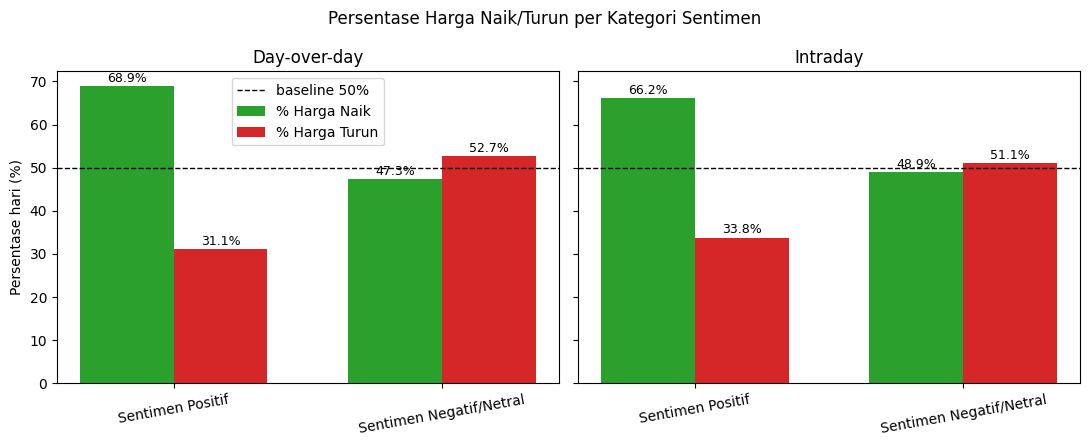

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, ringkas, title in zip(axes, [ringkas_dod, ringkas_intraday], ["Day-over-day", "Intraday"]):
    x = np.arange(len(ringkas))
    width = 0.35
    ax.bar(x - width / 2, ringkas["pct_harga_naik"], width, label="% Harga Naik", color="#2ca02c")
    ax.bar(x + width / 2, ringkas["pct_harga_turun"], width, label="% Harga Turun", color="#d62728")
    ax.axhline(50, color="black", linestyle="--", linewidth=1, label="baseline 50%")
    ax.set_xticks(x)
    ax.set_xticklabels(ringkas.index, rotation=10)
    ax.set_ylabel("Persentase hari (%)" if title == "Day-over-day" else "")
    ax.set_title(title)
    for i, (naik, turun) in enumerate(zip(ringkas["pct_harga_naik"], ringkas["pct_harga_turun"])):
        ax.text(i - width / 2, naik + 1, f"{naik}%", ha="center", fontsize=9)
        ax.text(i + width / 2, turun + 1, f"{turun}%", ha="center", fontsize=9)
axes[0].legend()
fig.suptitle("Persentase Harga Naik/Turun per Kategori Sentimen")
fig.tight_layout()
fig.savefig(FIG_DIR / "persentase_harga_per_kategori_sentimen.png", dpi=150)
plt.show()